<a href="https://colab.research.google.com/github/09StevenG/2022-ii-tutorial-git-repo-ejemplo/blob/main/Tarea3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [576]:
!pip install -q pysheds # Librería para el procesamiento rápido en DEM y
# análisis hidrológico


In [577]:
import rasterio #vamos a manejar rasters
from rasterio.warp import calculate_default_transform, reproject, Resampling
from rasterio import features
from rasterio.merge import merge
from rasterio.plot import show #para poder pre-visualizar

In [578]:
#casi todas estas las usamos para visualizar datos y geometrias
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import folium


In [579]:
#transformación de coordenadas
from shapely.geometry import shape
from pyproj import Transformer

In [580]:
import os #si vamos a generar archivos i/o (crear un archivo al disco o viceversa)
import math #calculos matematicos de cajón

In [581]:
# la libreria de pysheds
from pysheds.grid import Grid
print("Iniciar")

Iniciar


In [582]:
# Extraer mi DEM



In [583]:
import os
import math
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

import rasterio
from rasterio.merge import merge

# Esta línea le dice a la librería que no ande listando carpetas remotas.
# Sin ella, leer desde la nube es varias veces más lento.
os.environ["GDAL_DISABLE_READDIR_ON_OPEN"] = "EMPTY_DIR"

print("rasterio", rasterio.__version__)

rasterio 1.5.2


In [584]:
# área de interés: Río Colorado, Turrialba
LAT_MIN, LAT_MAX = 9.890000, 9.925000      # sur, norte
LON_MIN, LON_MAX = -83.710000, -83.645000  # oeste, este

NOMBRE_AREA = "Subcuenca Río Colorado"  # para los títulos de los mapas

print(f"Área: {NOMBRE_AREA}")
print(f"  latitud  de {LAT_MIN} a {LAT_MAX}")
print(f"  longitud de {LON_MIN} a {LON_MAX}")


Área: Subcuenca Río Colorado
  latitud  de 9.89 a 9.925
  longitud de -83.71 a -83.645


In [585]:
#acá se usan las funciones, queda la data del raster en z
z, perfil = obtener_dem(LAT_MIN, LON_MIN, LAT_MAX, LON_MAX)

Copernicus GLO-30 · 1 tesela(s)
234 x 126 celdas


In [586]:
#inspeccionar
print("Dimensiones :", z.shape, "(filas, columnas)")
print("CRS         :", perfil["crs"])
print("Valor nulo  :", perfil["nodata"])
print("Bandas      :", perfil["count"])
print("Tipo de dato:", perfil["dtype"])

Dimensiones : (126, 234) (filas, columnas)
CRS         : EPSG:4326
Valor nulo  : None
Bandas      : 1
Tipo de dato: float32


In [587]:
#verificar transform
t = perfil["transform"]

print(f"Tamaño de celda: {abs(t.a):.6f} x {abs(t.e):.6f} grados")
print(f"Es decir, unos {abs(t.a) * 111320:.0f} metros de lado")

Tamaño de celda: 0.000278 x 0.000278 grados
Es decir, unos 31 metros de lado


Archivo guardado como: Subcuenca_Río_Colorado_DEM.tif


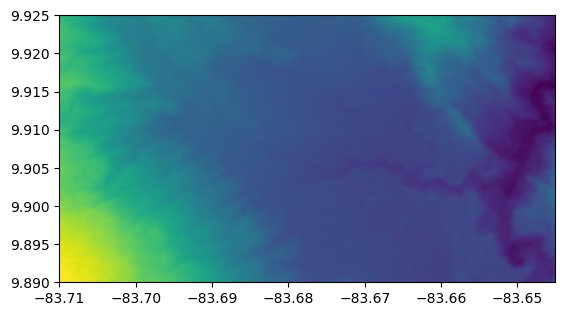

In [588]:
from rasterio.plot import show #para verlo



# Definir el nombre del archivo de salida
nombre_archivo = f"{NOMBRE_AREA.replace(' ', '_')}_DEM.tif"

# 1. Guardar el raster a un archivo GeoTIFF local usando el perfil actualizado
with rasterio.open(nombre_archivo, 'w', **perfil) as dst:
    dst.write(z, 1)

print(f"Archivo guardado como: {nombre_archivo}")

# 2. Volver a abrir el raster y leerlo para verificar y mostrar el mapa
with rasterio.open(nombre_archivo) as src:
    data_leida = src.read(1)

    show(src)

In [589]:
#el input de pysheds es un DEM
DEM = "Subcuenca_Río_Colorado_DEM.tif "

In [590]:
#funciones que deberíamos tener al alcance
def reproyectar(src_path, dst_path, dst_crs):
    """Pasa un ráster a otro sistema de coordenadas."""
    with rasterio.open(src_path) as src:
        t, w, h = calculate_default_transform(
            src.crs, dst_crs, src.width, src.height, *src.bounds)
        perfil = src.profile.copy()
        perfil.update(crs=dst_crs, transform=t, width=w, height=h, driver="GTiff")

        with rasterio.open(dst_path, "w", **perfil) as dst:
            reproject(source=rasterio.band(src, 1),
                      destination=rasterio.band(dst, 1),
                      src_transform=src.transform, src_crs=src.crs,
                      dst_transform=t, dst_crs=dst_crs,
                      src_nodata=src.nodata, dst_nodata=src.nodata,
                      resampling=Resampling.bilinear)
    return dst_path

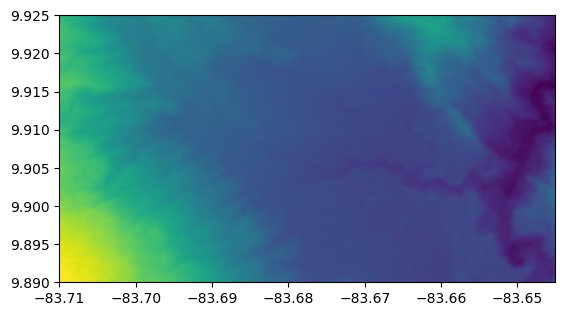

Zona UTM: EPSG:32617


In [591]:
with rasterio.open(DEM.strip()) as d:
    b = d.bounds #obtiene la caja del raster
    marco = gpd.GeoDataFrame(
        geometry=gpd.points_from_xy([b.left, b.right], [b.bottom, b.top]),
        crs=d.crs)
    UTM = marco.estimate_utm_crs() ## geopandas con un bound (caja en lat,lon)
    show(d) ##previsualizar el raster

print("Zona UTM:", UTM.to_string())

In [592]:
#reproyectamos este raster
reproyectar(DEM.strip(), "Subcuenca_Río_Colorado_DEM.tif", UTM)

'Subcuenca_Río_Colorado_DEM.tif'

Dimensiones: 235 x 129
Celda      : 30.54 x 30.54 m
Área de celda: 933 m2


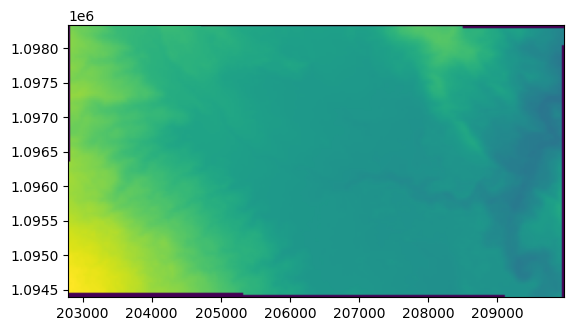

In [593]:
with rasterio.open("Subcuenca_Río_Colorado_DEM.tif") as d:
    print("Dimensiones:", d.width, "x", d.height)
    print(f"Celda      : {abs(d.transform.a):.2f} x {abs(d.transform.e):.2f} m")
    CELDA = abs(d.transform.a) * abs(d.transform.e)
    print(f"Área de celda: {CELDA:.0f} m2")
    show(d)

In [594]:
##paso 2 - acondicionamiento del terreno
## paso 2.1 leer el raster con Pysheds
grid = Grid.from_raster("Subcuenca_Río_Colorado_DEM.tif")
dem  = grid.read_raster("Subcuenca_Río_Colorado_DEM.tif")

/usr/local/lib/python3.13/dist-packages/pysheds/io.py:134: UserWarning: No `nodata` value detected. Defaulting to 0.
  warnings.warn('No `nodata` value detected. Defaulting to 0.')
/usr/local/lib/python3.13/dist-packages/pysheds/io.py:134: UserWarning: No `nodata` value detected. Defaulting to 0.
  warnings.warn('No `nodata` value detected. Defaulting to 0.')


In [595]:
#acondicionar el terreno, (fill_pits, fill_depressions,resolve_flats)


pit      = grid.fill_pits(dem) #ajustar pixeles aislados que estén hundidos o salidos
flood    = grid.fill_depressions(pit) ## los rellenamos
inflated = grid.resolve_flats(flood) ##pendiente artificial ( ajustados)

print("celdas modificadas por fill_pits        :",
      int((np.asarray(pit) != np.asarray(dem)).sum()))
print("celdas modificadas por fill_depressions :",
      int((np.asarray(flood) != np.asarray(pit)).sum()))

celdas modificadas por fill_pits        : 1279
celdas modificadas por fill_depressions : 0


In [596]:
##algebra de mapas, vamos a comparar visualmente pixels que fueron cambiados
diferencia = np.asarray(inflated) - np.asarray(dem) #determinar diferencias entre original y acondicionado
tocadas = diferencia > 0 #pixels modificados

print(f"Celdas modificadas  : {int(tocadas.sum()):,} de {diferencia.size:,} "
      f"({tocadas.sum()/diferencia.size*100:.2f} %)")
if tocadas.any():
    print(f"Levantamiento medio : {diferencia[tocadas].mean():.3f} m")
    print(f"Levantamiento máximo: {diferencia[tocadas].max():.2f} m")

Celdas modificadas  : 1,768 de 30,315 (5.83 %)
Levantamiento medio : 2.525 m
Levantamiento máximo: 39.29 m


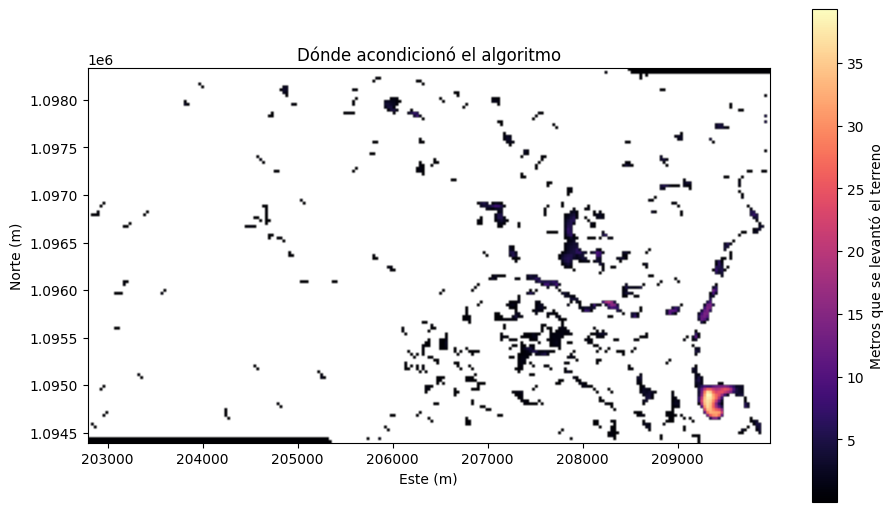

In [597]:
plt.figure(figsize=(11, 8))
plt.imshow(np.where(tocadas, diferencia, np.nan), cmap="magma",
           extent=grid.extent)
plt.colorbar(label="Metros que se levantó el terreno", shrink=0.8)
plt.title("Dónde acondicionó el algoritmo")
plt.xlabel("Este (m)"); plt.ylabel("Norte (m)")
plt.show()

In [598]:
##paso 3 calculo de dirección de flujo
dirmap = (64, 128, 1, 2, 4, 8, 16, 32)
#          N  NE   E  SE  S  SO   O  NO

fdir = grid.flowdir(inflated, dirmap=dirmap)

print("Direcciones calculadas:", fdir.shape)
print("Valores que aparecen  :", sorted(np.unique(np.asarray(fdir))[:10]))

Direcciones calculadas: (129, 235)
Valores que aparecen  : [np.int64(-2), np.int64(-1), np.int64(0), np.int64(1), np.int64(2), np.int64(4), np.int64(8), np.int64(16), np.int64(32), np.int64(64)]


In [599]:
#paso 4 calculo de acumuliación
acc = grid.accumulation(fdir, dirmap=dirmap)
a = np.asarray(acc)          # copia NumPy, para contar y graficar

print(f"Acumulación máxima: {int(a.max()):,} celdas")
print(f"Es decir, el cauce principal drena {a.max()*CELDA/1e6:,.0f} km2")

Acumulación máxima: 26,252 celdas
Es decir, el cauce principal drena 24 km2


In [600]:
#para verificar la red de drenaje se debe definir un umbral
for u in [100, 500, 1000, 5000, 20000]:
    n = int((a > u).sum())
    print(f"umbral {u:>6,} celdas ({u*CELDA/1e6:6.2f} km2) -> "
          f"{n:>7,} celdas de cauce ~ {n*abs(grid.affine.a)/1000:7.1f} km de red")

umbral    100 celdas (  0.09 km2) ->   2,085 celdas de cauce ~    63.7 km de red
umbral    500 celdas (  0.47 km2) ->     932 celdas de cauce ~    28.5 km de red
umbral  1,000 celdas (  0.93 km2) ->     566 celdas de cauce ~    17.3 km de red
umbral  5,000 celdas (  4.66 km2) ->     182 celdas de cauce ~     5.6 km de red
umbral 20,000 celdas ( 18.66 km2) ->     106 celdas de cauce ~     3.2 km de red


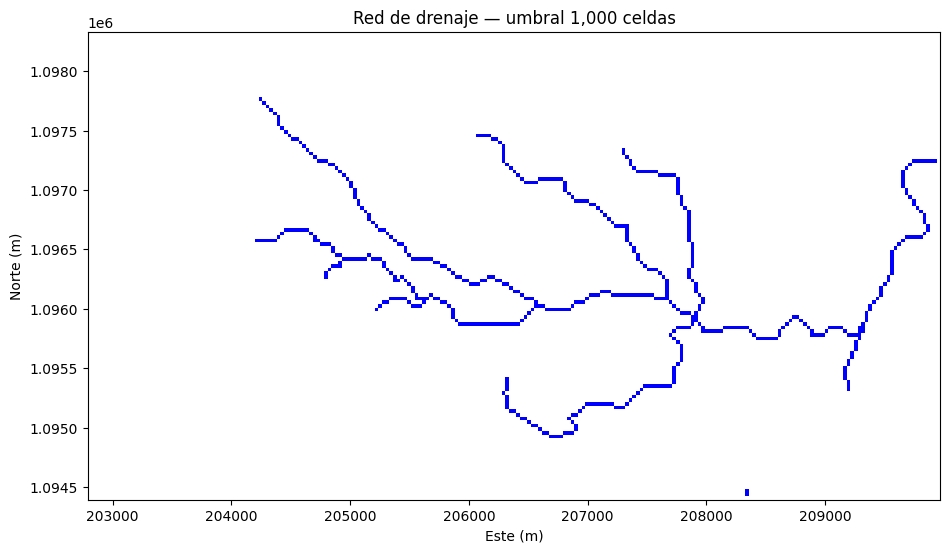

In [601]:
UMBRAL = 1000          # celdas; ~0.9 km2 de área drenada

# Ojo: cauces se deja como objeto de pysheds, no como arreglo de NumPy.
# snap_to_mask lo necesita así. Para dibujar usamos np.asarray(cauces).
cauces = acc > UMBRAL
cauces_np = np.asarray(cauces)

plt.figure(figsize=(11, 9))
plt.imshow(np.where(cauces_np, 1, np.nan), cmap="winter", extent=grid.extent)
plt.title(f"Red de drenaje — umbral {UMBRAL:,} celdas")
plt.xlabel("Este (m)"); plt.ylabel("Norte (m)")
plt.show()

In [602]:
hacia_utm_p = Transformer.from_crs("EPSG:4326", UTM, always_xy=True)
x0p, y0p = hacia_utm_p.transform(-83.674198,9.903764)


def probar(etiqueta, superficie):
    fd = grid.flowdir(superficie, dirmap=dirmap)
    ac = grid.accumulation(fd, dirmap=dirmap)
    sx, sy = grid.snap_to_mask(ac > UMBRAL, (x0p, y0p))
    cu = grid.catchment(x=sx, y=sy, fdir=fd, dirmap=dirmap, xytype="coordinate")
    print(f"{etiqueta:32s} acc máx {int(np.asarray(ac).max()):>9,} | "
          f"cuenca {np.asarray(cu).sum()*CELDA/1e6:7.2f} km2")


probar("1. crudo, sin acondicionar", dem)
probar("2. solo fill_pits", pit)
probar("3. + fill_depressions", flood)
probar("4. + resolve_flats (completo)", inflated)

1. crudo, sin acondicionar       acc máx     1,250 | cuenca    1.16 km2
2. solo fill_pits                acc máx     1,266 | cuenca    1.18 km2
3. + fill_depressions            acc máx     1,266 | cuenca    1.18 km2
4. + resolve_flats (completo)    acc máx    26,252 | cuenca    8.37 km2


In [603]:
LON_SALIDA, LAT_SALIDA = -83.674198,9.903764
hacia_utm = Transformer.from_crs("EPSG:4326", UTM, always_xy=True)
hacia_geo = Transformer.from_crs(UTM, "EPSG:4326", always_xy=True)

x0, y0 = hacia_utm.transform(LON_SALIDA, LAT_SALIDA) #mi punto
x, y = grid.snap_to_mask(cauces, (x0, y0)) ### se debe SNAP_to_MASK (pedirle al pysheds que
#                                          ### lo coloque sobre el punto de la red de drenaje mas cercana
##pysheds por medio de este método snap_to_mask determina el pour point correcto.

print(f"Punto dado  : {LON_SALIDA}, {LAT_SALIDA}")
print(f"Punto pegado: {hacia_geo.transform(x, y)[0]:.5f}, {hacia_geo.transform(x, y)[1]:.5f}")
print(f"Se movió {((x-x0)**2 + (y-y0)**2)**0.5:.0f} metros")

Punto dado  : -83.674198, 9.903764
Punto pegado: -83.67421, 9.90431
Se movió 61 metros


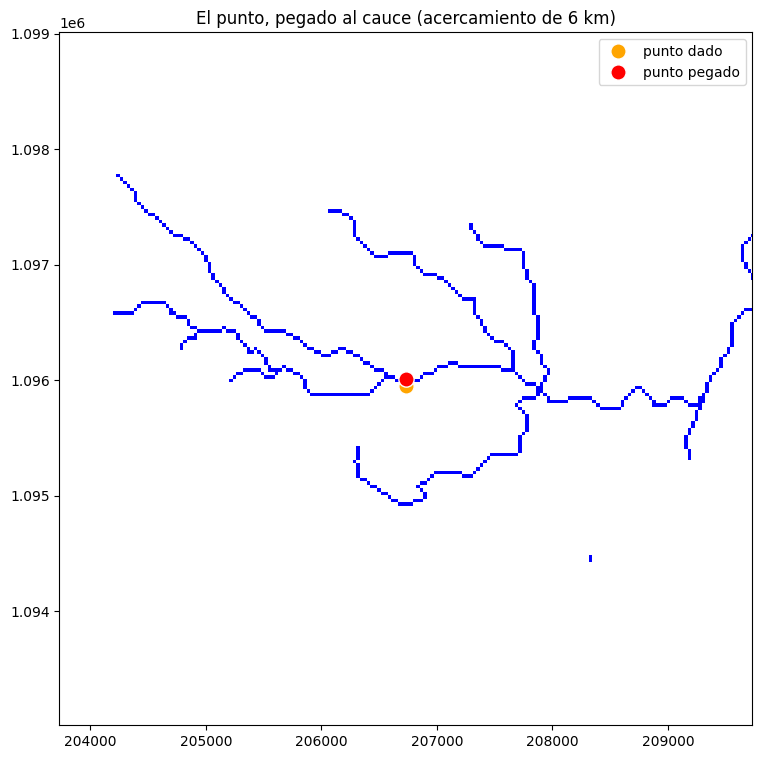

In [604]:
fig, ax = plt.subplots(figsize=(10, 9))
ax.imshow(np.where(cauces_np, 1, np.nan), cmap="winter", extent=grid.extent)
ax.plot(x0, y0, "o", color="orange", markersize=11,
        markeredgecolor="white", label="punto dado")
ax.plot(x, y, "o", color="red", markersize=11,
        markeredgecolor="white", label="punto pegado")
ax.set_xlim(x - 3000, x + 3000)
ax.set_ylim(y - 3000, y + 3000)
ax.legend()
ax.set_title("El punto, pegado al cauce (acercamiento de 6 km)")
plt.show()

In [605]:
##
cuenca = grid.catchment(x=x, y=y, fdir=fdir, dirmap=dirmap,
                        xytype="coordinate")
m = np.asarray(cuenca)
n_celdas = int(m.sum())

print(f"{n_celdas:,} celdas")
print(f"Área: {n_celdas * CELDA / 1000000:.2f} km2")

8,976 celdas
Área: 8.37 km2


In [606]:
mask = m.astype(np.uint8)
polis = [shape(g) for g, v in features.shapes(mask, mask=m, transform=grid.affine)
         if v == 1]

gdf = gpd.GeoDataFrame(geometry=polis, crs=UTM).dissolve() ##geometria de la cuenca

A = gdf.area.iloc[0]
P = gdf.length.iloc[0]

print(f"Área      : {A/1e6:.2f} km2")
print(f"Perímetro : {P/1000:.2f} km")

Área      : 8.37 km2
Perímetro : 17.04 km


In [607]:
#ya podemos caracterizar la cuenca o el análisis morfométrico de la cuenca
#los valorres para hacer esto vienen del DEM
z_cuenca = np.asarray(dem)[m]
res = abs(grid.affine.a)

gy, gx = np.gradient(np.asarray(inflated), res)
pend = np.degrees(np.arctan(np.sqrt(gx**2 + gy**2)))

red_interna = cauces_np & m
long_red = red_interna.sum() * res / 1000

print(f"Área                 : {A/1e6:.2f} km2")
print(f"Perímetro            : {P/1000:.2f} km")
print(f"Elevación mínima     : {z_cuenca.min():.0f} msnm")
print(f"Elevación máxima     : {z_cuenca.max():.0f} msnm")
print(f"Elevación media      : {z_cuenca.mean():.0f} msnm")
print(f"Desnivel             : {z_cuenca.max() - z_cuenca.min():.0f} m")
print(f"Pendiente media      : {pend[m].mean():.1f}°  ({np.tan(np.radians(pend[m].mean()))*100:.0f} %)")
print(f"Pendiente máxima     : {pend[m].max():.1f}°  ({np.tan(np.radians(pend[m].max()))*100:.0f} %)")
print(f"Longitud de cauces   : {long_red:.1f} km")
print(f"Densidad de drenaje  : {long_red/(A/1e6):.2f} km/km2")


Área                 : 8.37 km2
Perímetro            : 17.04 km
Elevación mínima     : 596 msnm
Elevación máxima     : 1180 msnm
Elevación media      : 821 msnm
Desnivel             : 584 m
Pendiente media      : 11.8°  (21 %)
Pendiente máxima     : 86.5°  (1618 %)
Longitud de cauces   : 6.0 km
Densidad de drenaje  : 0.72 km/km2


In [608]:
#extraer la cuenca
gdf_geo = gdf.to_crs("EPSG:4326") ### regresar la cuenca de utm a lat,lon
lon_s, lat_s = hacia_geo.transform(x, y) #pour point

#mapa = folium.Map(location=[lat_s, lon_s], zoom_start=12, tiles="OpenStreetMap")

mapa = folium.Map(
    location=[lat_s, lon_s],
    zoom_start=12,
    tiles="https://{s}.tile.opentopomap.org/{z}/{x}/{y}.png",
    attr='&copy; <a href="https://www.openstreetmap.org/copyright">OpenStreetMap</a> contributors',
    referrer_policy="no-referrer-when-downgrade" # Esto permite enviar el origen
)
#
folium.GeoJson(
    gdf_geo,
    name="Cuenca",
    style_function=lambda f: {"fillColor": "#FF0000", "color": "#FF0000",
                              "weight": 2, "fillOpacity": 0.15}
).add_to(mapa)

folium.CircleMarker([lat_s, lon_s], radius=7, color="white", weight=2,
                    fill=True, fill_color="red", fill_opacity=1,
                    tooltip="Punto de salida").add_to(mapa)

folium.LayerControl().add_to(mapa)
mapa

In [612]:
#exportar la cuenca
gdf_geo.to_file("micro_cuenca_delimitada.geojson", driver="GeoJSON")

verif = gpd.read_file("micro_cuenca_delimitada.geojson")
print("Guardado y verificado")
print("  CRS :", verif.crs)
print("  área:", f"{verif.to_crs(UTM).area.iloc[0]/1e6:.2f} km2")

Guardado y verificado
  CRS : EPSG:4326
  área: 8.37 km2
